# 🏭 Прогноз температуры стали

## Описание проекта

Металлургический комбинат стремится сократить энергозатраты на этапе обработки стали.  
Один из ключевых параметров процесса — **температура расплавленного металла**.

### Цель проекта
Построить модель машинного обучения для предсказания **последней измеренной температуры стали в партии**.

- **Тип задачи**: регрессия  
- **Целевая метрика**: MAE (Mean Absolute Error)  
- **Требование заказчика**: MAE ≤ 6.8  

---

## План работы

1. Загрузка данных  
2. Анализ и предобработка отдельных датасетов  
3. Агрегация данных по партиям  
4. Объединение данных  
5. Анализ объединённого датасета  
6. Подготовка данных  
7. Обучение моделей  
8. Выбор лучшей модели и выводы  

---

## Шаг 1. Загрузка данных

На этом этапе загружаем все предоставленные датасеты и выполняем их первичный осмотр:  
проверяем размеры таблиц и структуру данных.

---

## Шаг 2. Анализ и предобработка отдельных датасетов

Датасеты анализируются отдельно, чтобы:

- понять структуру данных,  
- выявить пропуски и аномалии,  
- определить способ агрегации по партиям.

### Температура
- Температура измеряется несколько раз в рамках одной партии.  
- Для каждой партии:
  - **последняя температура** используется как таргет,  
  - партии с одним замером исключаются,  
  - вычисляются агрегированные признаки (например, среднее, размах, количество замеров).

### Электроды
- На основе времени начала и окончания нагрева вычисляется **длительность нагрева**.  
- Активная и реактивная мощности агрегируются по партиям (сумма, среднее и т.д.).

### Сыпучие и проволочные материалы
- Пропуски в данных означают **отсутствие подачи материала**, поэтому заменяются на нули.  
- Данные агрегируются по партиям (общий объём подачи по каждому материалу).

### Газ
- Объём поданного инертного газа агрегируется по партиям и используется как признак.
---

## Шаг 3. Объединение данных

Все агрегированные датасеты объединяются по ключу `key`.  
В результате формируется таблица, где:

- одна строка соответствует одной партии,  
- используются только партии, присутствующие во всех источниках данных.

---

## Шаг 4. Анализ объединённого датасета

После объединения данных:

- анализируются распределения признаков,  
- проводится корреляционный анализ,  
- оценивается вклад признаков в таргет.

---

## Шаг 5. Подготовка данных

- Данные разделяются на обучающую и тестовую выборки (`train_test_split`).  
- Числовые признаки масштабируются (например, с помощью `StandardScaler`) для корректной работы моделей.

---

## Шаг 6. Обучение моделей

Для решения задачи были обучены следующие модели машинного обучения:

- **DummyRegressor** — базовая модель для проверки адекватности решения.
- **Ridge Regression** — линейная модель с регуляризацией, используемая
  для оценки линейных зависимостей между признаками и целевой переменной.
- **RandomForestRegressor** — ансамблевая модель, устойчивая к выбросам
  и способная учитывать нелинейные зависимости.
- **XGBoostRegressor** — градиентный бустинг над деревьями решений,
  используемый как основная модель. Для неё выполнен подбор гиперпараметров
  с использованием кросс-валидации.

Сравнение моделей позволяет выбрать оптимальное решение
с точки зрения качества и устойчивости.

---

## Шаг 7. Выбор лучшей модели

- Лучшая модель выбирается на основе качества на **кросс-валидации**.  
- Тестовая выборка используется **только для финальной оценки** MAE.


## Шаг 8. Выводы

В рамках проекта:

✅ Подготовлены данные для моделирования  
✅ Обучены и сравнены модели машинного обучения  
✅ Достигнуто требуемое качество по метрике **MAE ≤ 6.8**  
✅ Определены ключевые факторы, влияющие на температуру стали

**Результат**: Полученная модель может использоваться для имитации технологического процесса и оптимизации энергозатрат на производстве.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import warnings
from sklearn.model_selection import KFold
warnings.filterwarnings('ignore')

# Настройка визуализации
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)

print(" Библиотеки успешно загружены")

 Библиотеки успешно загружены


In [2]:
# Шаг 1 - Загрузка данных
print("="*70)
print("ШАГ 1. ЗАГРУЗКА ДАННЫХ")
print("="*70)

DATA_PATH = './'

data_arc = pd.read_csv(DATA_PATH + 'data_arc_new.csv')
data_bulk = pd.read_csv(DATA_PATH + 'data_bulk_new.csv')
data_bulk_time = pd.read_csv(DATA_PATH + 'data_bulk_time_new.csv')
data_gas = pd.read_csv(DATA_PATH + 'data_gas_new.csv')
data_temp = pd.read_csv(DATA_PATH + 'data_temp_new.csv')
data_wire = pd.read_csv(DATA_PATH + 'data_wire_new.csv')
data_wire_time = pd.read_csv(DATA_PATH + 'data_wire_time_new.csv')

print("\n Размеры загруженных датасетов:")
datasets_info = {
    'Температура': data_temp.shape,
    'Электроды': data_arc.shape,
    'Сыпучие материалы': data_bulk.shape,
    'Время сыпучих': data_bulk_time.shape,
    'Газ': data_gas.shape,
    'Проволока': data_wire.shape,
    'Время проволоки': data_wire_time.shape
}

for name, shape in datasets_info.items():
    print(f"  • {name:20s}: {shape[0]:4d} строк × {shape[1]:2d} столбцов")

print("\n Все данные успешно загружены из папки:", DATA_PATH)

ШАГ 1. ЗАГРУЗКА ДАННЫХ

 Размеры загруженных датасетов:
  • Температура         : 18092 строк ×  3 столбцов
  • Электроды           : 14876 строк ×  5 столбцов
  • Сыпучие материалы   : 3129 строк × 16 столбцов
  • Время сыпучих       : 3129 строк × 16 столбцов
  • Газ                 : 3239 строк ×  2 столбцов
  • Проволока           : 3081 строк × 10 столбцов
  • Время проволоки     : 3081 строк × 10 столбцов

 Все данные успешно загружены из папки: ./


In [3]:
#  Первичный осмотр структуры
print("\n Первичный осмотр структуры данных:\n")

print("1. Температура (первые 3 строки):")
display(data_temp.head(3))

print("\n2. Электроды (первые 3 строки):")
display(data_arc.head(3))

print("\n3. Базовая информация о температуре:")
print(data_temp.info())


 Первичный осмотр структуры данных:

1. Температура (первые 3 строки):


,key,Время замера,Температура
0,1,2019-05-03 11:02:04,1571.0
1,1,2019-05-03 11:07:18,1604.0
2,1,2019-05-03 11:11:34,1618.0



2. Электроды (первые 3 строки):


,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305130,0.211253
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.765658,0.477438
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580313,0.430460



3. Базовая информация о температуре:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18092 entries, 0 to 18091
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   key           18092 non-null  int64  
 1   Время замера  18092 non-null  object 
 2   Температура   14665 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 424.2+ KB
None


### Вывод по шагу 1. Загрузка и первичный осмотр данных

Все датасеты успешно загружены из локальной директории.

Данные представлены в нескольких таблицах, каждая из которых описывает
отдельный аспект технологического процесса и связана по ключу `key`
(номер партии).

Количество строк в датасетах различается:
- температурные и электрические данные содержат значительно больше записей,
  так как фиксируются на каждом этапе обработки;
- данные по сыпучим материалам, проволоке и газу представлены
  в агрегированном виде по партиям.

В датасете температуры обнаружены пропуски в столбце `Температура`,
что потребует дополнительной обработки на следующих этапах.
Типы данных соответствуют ожидаемым:
временные признаки представлены строками, числовые — в формате `float` и `int`.

На данном этапе данные считаются корректно загруженными
и готовы к детальному исследовательскому анализу.


In [4]:
# Шаг 2.1 - Анализ температуры (ДО агрегации)
# ===============================
print("\n" + "="*70)
print("ШАГ 2. АНАЛИЗ И ПРЕДОБРАБОТКА ОТДЕЛЬНЫХ ДАТАСЕТОВ")
print("="*70)
print("\n2.1  ТЕМПЕРАТУРА (анализ ДО агрегации)")

# Статистика
print("\nСтатистическое описание температуры:")
display(data_temp['Температура'].describe())

# Количество замеров на партию
temp_counts = data_temp.groupby('key').size()
print(f"\n Анализ количества замеров:")
print(f"  • Среднее замеров на партию: {temp_counts.mean():.2f}")
print(f"  • Партий с 1 замером: {(temp_counts == 1).sum()} (будут исключены)")
print(f"  • Партий с 2+ замерами: {(temp_counts >= 2).sum()} (используем)")


ШАГ 2. АНАЛИЗ И ПРЕДОБРАБОТКА ОТДЕЛЬНЫХ ДАТАСЕТОВ

2.1  ТЕМПЕРАТУРА (анализ ДО агрегации)

Статистическое описание температуры:


count    14665.000000
mean      1590.722741
std         20.394381
min       1191.000000
25%       1580.000000
50%       1590.000000
75%       1599.000000
max       1705.000000
Name: Температура, dtype: float64


 Анализ количества замеров:
  • Среднее замеров на партию: 5.63
  • Партий с 1 замером: 2 (будут исключены)
  • Партий с 2+ замерами: 3214 (используем)


In [1]:
# Визуализация
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. Общая гистограмма температуры
ax1 = fig.add_subplot(gs[0, :2])
ax1.hist(data_temp['Температура'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
ax1.axvline(data_temp['Температура'].mean(), color='red', linestyle='--', 
            linewidth=2.5, label=f"Среднее: {data_temp['Температура'].mean():.1f}°C")
ax1.set_title('Распределение температуры (все замеры)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Температура (°C)', fontsize=11)
ax1.set_ylabel('Частота', fontsize=11)
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)

# 2. Boxplot температуры
ax2 = fig.add_subplot(gs[0, 2])
sns.boxplot(
    y=data_temp['Температура'],
    ax=ax2,
    color='lightblue'
)
ax2.set_title('Boxplot температуры', fontsize=12, fontweight='bold')
ax2.set_ylabel('Температура (°C)')
ax2.grid(alpha=0.3)

# 3. Количество замеров на партию
ax3 = fig.add_subplot(gs[1, 0])
ax3.hist(temp_counts, bins=25, edgecolor='black', alpha=0.7, color='green')
ax3.set_title('Замеры на партию', fontsize=12, fontweight='bold')
ax3.set_xlabel('Количество замеров', fontsize=10)
ax3.set_ylabel('Число партий', fontsize=10)
ax3.grid(alpha=0.3)

# 4. Динамика температуры (примеры)
ax4 = fig.add_subplot(gs[1, 1:])
sample_keys = data_temp['key'].unique()[:7]
for key in sample_keys:
    batch = data_temp[data_temp['key'] == key].copy()
    batch['Время замера'] = pd.to_datetime(batch['Время замера'])
    batch = batch.sort_values('Время замера').reset_index(drop=True)
    ax4.plot(batch.index, batch['Температура'], marker='o', 
             linewidth=2, markersize=6, alpha=0.7, label=f'Партия {key}')
ax4.set_title('Динамика температуры (примеры партий)', fontsize=12, fontweight='bold')
ax4.set_xlabel('Номер замера', fontsize=10)
ax4.set_ylabel('Температура (°C)', fontsize=10)
ax4.legend(ncol=2, fontsize=8)
ax4.grid(alpha=0.3)

# 5. Статистика по партиям
ax5 = fig.add_subplot(gs[2, :])
value_counts = temp_counts.value_counts().sort_index()
ax5.bar(value_counts.index, value_counts.values, edgecolor='black', alpha=0.7, color='coral')
ax5.set_title('Распределение партий по количеству замеров', fontsize=12, fontweight='bold')
ax5.set_xlabel('Количество замеров в партии', fontsize=10)
ax5.set_ylabel('Количество партий', fontsize=10)
ax5.grid(alpha=0.3, axis='y')

plt.suptitle('АНАЛИЗ ТЕМПЕРАТУРЫ (ДО АГРЕГАЦИИ)', fontsize=16, fontweight='bold', y=0.995)
plt.show()

NameError: name 'plt' is not defined

## Шаг 2.1. Анализ температуры (до агрегации)

На данном этапе выполнен исследовательский анализ измерений температуры **до объединения и агрегации данных**.

### Основные наблюдения

- Всего доступно **14 665 корректных измерений температуры**.
- Средняя температура составляет **≈ 1590.7 °C**, медиана — **1590 °C**, что говорит о симметричном распределении.
- Основная масса значений лежит в диапазоне **1550–1620 °C**.
- Минимальное значение (**1191 °C**) и максимальное (**1705 °C**) встречаются редко и требуют учета при моделировании.

### Количество замеров по партиям

- Среднее число замеров температуры на одну партию — **≈ 5.6**.
- Обнаружены партии с **одним замером температуры** (2 партии).
- Такие партии не позволяют корректно определить целевую переменную и **будут исключены**.
- Для дальнейшего анализа и моделирования используются партии с **двумя и более замерами** (3214 партий).

### Динамика температуры внутри партий

- Температура внутри одной партии **изменяется нелинейно** и зависит от этапов нагрева и добавления материалов.
- Для разных партий число замеров различается (от 2 до ~17), что делает невозможным использование временных рядов.
- Последний замер температуры логично использовать как **целевую переменную**, а промежуточные значения — агрегировать.

### Вывод

- Температура является стабильной и информативной переменной.
- Для каждой партии будет использоваться:
  - **последний замер температуры** — в качестве таргета;
  - агрегированные характеристики (mean, min, max, std и др.) — в качестве признаков.
- Такой подход позволяет унифицировать партии с разным количеством этапов и избежать утечки данных.



2.2  ЭЛЕКТРОДЫ (анализ ДО агрегации)

Статистика электродов:


,Активная мощность,Реактивная мощность,heating_duration
count,14876.000000,14876.000000,14876.000000
mean,0.662752,0.438986,2.861182
std,0.258885,5.873485,1.636447
min,0.223120,-715.479924,0.183333
25%,0.467115,0.337175,1.783333
50%,0.599587,0.441639,2.450000
75%,0.830070,0.608201,3.566667
max,1.463773,1.270284,15.116667


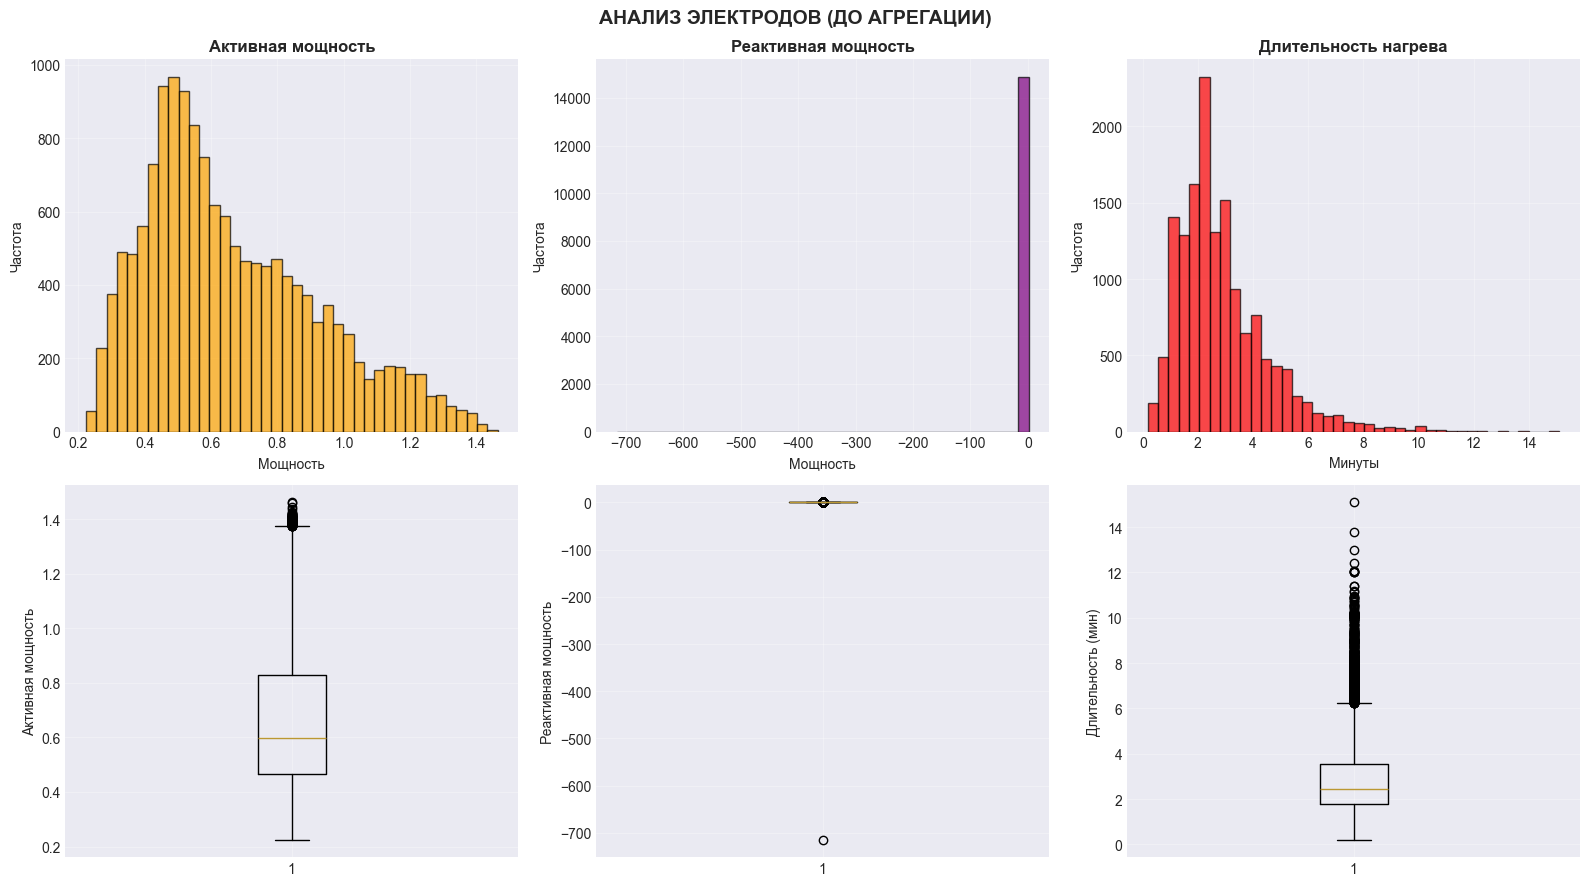

In [6]:
# Шаг 2.2 - Анализ электродов
# ===============================
print("\n2.2  ЭЛЕКТРОДЫ (анализ ДО агрегации)")

# Преобразование времени и расчёт длительности
data_arc['Начало нагрева дугой'] = pd.to_datetime(data_arc['Начало нагрева дугой'])
data_arc['Конец нагрева дугой'] = pd.to_datetime(data_arc['Конец нагрева дугой'])
data_arc['heating_duration'] = (
    data_arc['Конец нагрева дугой'] - data_arc['Начало нагрева дугой']
).dt.total_seconds() / 60  # в минутах

print("\nСтатистика электродов:")
display(data_arc[['Активная мощность', 'Реактивная мощность', 'heating_duration']].describe())

# Визуализация
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('АНАЛИЗ ЭЛЕКТРОДОВ (ДО АГРЕГАЦИИ)', fontsize=14, fontweight='bold')

# Активная мощность
axes[0, 0].hist(data_arc['Активная мощность'], bins=40, edgecolor='black', 
                alpha=0.7, color='orange')
axes[0, 0].set_title('Активная мощность', fontweight='bold')
axes[0, 0].set_xlabel('Мощность')
axes[0, 0].set_ylabel('Частота')
axes[0, 0].grid(alpha=0.3)

axes[1, 0].boxplot(data_arc['Активная мощность'], vert=True)
axes[1, 0].set_ylabel('Активная мощность')
axes[1, 0].grid(alpha=0.3)

# Реактивная мощность
axes[0, 1].hist(data_arc['Реактивная мощность'], bins=40, edgecolor='black', 
                alpha=0.7, color='purple')
axes[0, 1].set_title('Реактивная мощность', fontweight='bold')
axes[0, 1].set_xlabel('Мощность')
axes[0, 1].set_ylabel('Частота')
axes[0, 1].grid(alpha=0.3)

axes[1, 1].boxplot(data_arc['Реактивная мощность'], vert=True)
axes[1, 1].set_ylabel('Реактивная мощность')
axes[1, 1].grid(alpha=0.3)

# Длительность нагрева
axes[0, 2].hist(data_arc['heating_duration'], bins=40, edgecolor='black', 
                alpha=0.7, color='red')
axes[0, 2].set_title('Длительность нагрева', fontweight='bold')
axes[0, 2].set_xlabel('Минуты')
axes[0, 2].set_ylabel('Частота')
axes[0, 2].grid(alpha=0.3)

axes[1, 2].boxplot(data_arc['heating_duration'], vert=True)
axes[1, 2].set_ylabel('Длительность (мин)')
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Шаг 2.2. Анализ электродов (до агрегации)

На данном этапе выполнен исследовательский анализ данных по работе электродов **до агрегации по партиям**.

### Основные статистики

- Всего зафиксировано **14 876 интервалов нагрева**.
- Активная мощность:
  - среднее значение — **≈ 0.66**,
  - межквартильный диапазон — **0.47–0.83**,
  - распределение смещено вправо, присутствуют высокие значения.
- Реактивная мощность:
  - среднее значение — **≈ 0.44**,
  - обнаружены **отрицательные значения**, включая экстремальные выбросы.
- Длительность нагрева:
  - среднее значение — **≈ 2.86 минуты**,
  - большинство нагревов длится **до 4 минут**,
  - присутствует длинный правый хвост (редкие длительные нагревы).

### Анализ распределений

- Активная мощность имеет асимметричное распределение с редкими высокими значениями, что характерно для реального промышленного процесса.
- Реактивная мощность содержит **аномальные отрицательные значения**, которые физически не интерпретируются как полезная мощность.
- Длительность нагрева имеет выраженную правостороннюю асимметрию и выбросы, что отражает различие технологических режимов.

### Выбросы и аномалии

- Отрицательные значения реактивной мощности рассматриваются как **технологические аномалии**.
- Длительные нагревы не являются ошибками, так как могут быть обусловлены особенностями конкретных партий.
- Статистические выбросы не удаляются на данном этапе, чтобы сохранить реальное распределение данных.

### Вывод

- Данные по электродам содержат важную информацию о процессе нагрева стали.
- Для унификации партий с разным числом этапов нагрева:
  - будет рассчитана **длительность нагрева**;
  - данные будут агрегированы по партиям (sum, mean, max).
- Аномальные значения будут дополнительно учтены на этапе подготовки данных и моделирования.



2.3  СЫПУЧИЕ МАТЕРИАЛЫ (анализ ДО агрегации)

 Анализ пропусков:
   Всего значений: 50,064
   Пропусков: 35,776 (71.5%)

 Топ-10 признаков с наибольшим числом пропусков:
  • Bulk 8    : 3128 (100.0%)
  • Bulk 13   : 3111 ( 99.4%)
  • Bulk 9    : 3110 ( 99.4%)
  • Bulk 2    : 3107 ( 99.3%)
  • Bulk 7    : 3104 ( 99.2%)
  • Bulk 5    : 3052 ( 97.5%)
  • Bulk 10   : 2953 ( 94.4%)
  • Bulk 11   : 2952 ( 94.3%)
  • Bulk 1    : 2877 ( 91.9%)
  • Bulk 6    : 2553 ( 81.6%)


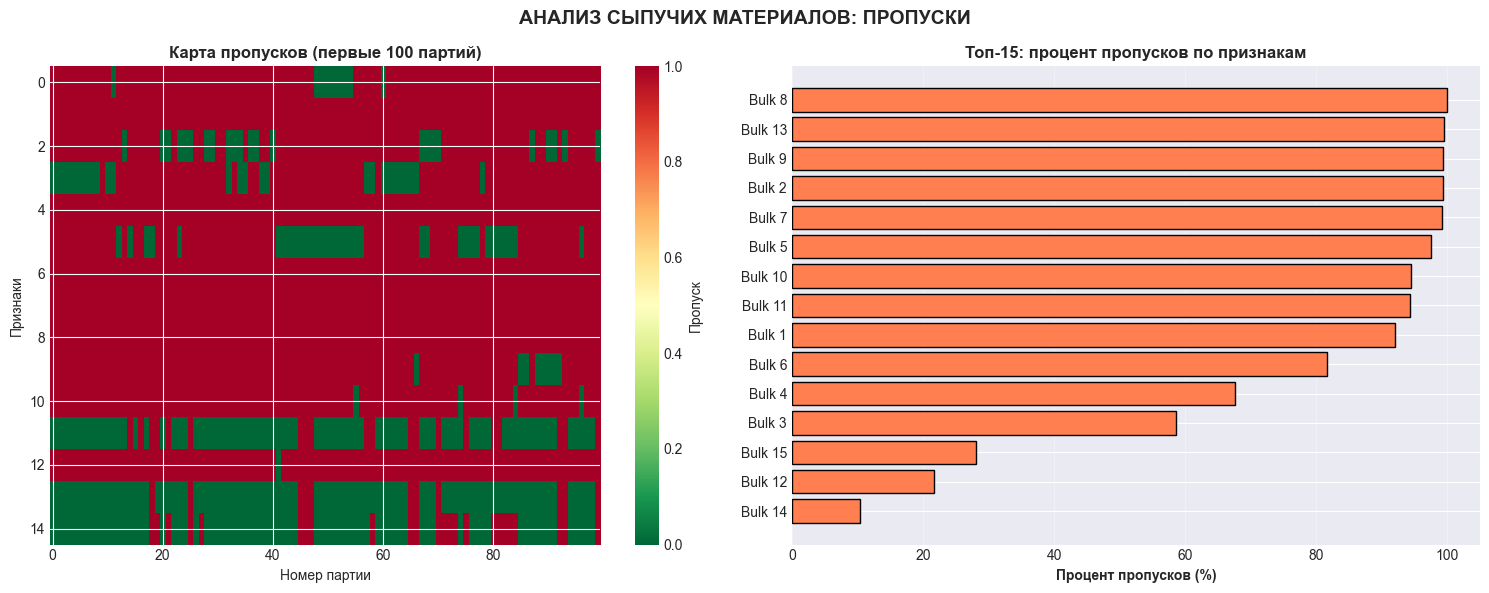

In [7]:
# Шаг 2.3 - Анализ сыпучих материалов
print("\n2.3  СЫПУЧИЕ МАТЕРИАЛЫ (анализ ДО агрегации)")

# Анализ пропусков
missing_count = data_bulk.isnull().sum().sum()
total_values = data_bulk.size
missing_pct = missing_count / total_values * 100

print(f"\n Анализ пропусков:")
print(f"   Всего значений: {total_values:,}")
print(f"   Пропусков: {missing_count:,} ({missing_pct:.1f}%)")

# Топ-10 признаков с пропусками
missing_by_col = data_bulk.isnull().sum().sort_values(ascending=False)
missing_by_col = missing_by_col[missing_by_col > 0]

print(f"\n Топ-10 признаков с наибольшим числом пропусков:")
top10_missing = missing_by_col.head(10)
for col, count in top10_missing.items():
    pct = count / len(data_bulk) * 100
    print(f"  • {col:10s}: {count:4d} ({pct:5.1f}%)")

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('АНАЛИЗ СЫПУЧИХ МАТЕРИАЛОВ: ПРОПУСКИ', fontsize=14, fontweight='bold')

# 1. Heatmap пропусков (первые 100 партий)
missing_matrix = data_bulk.iloc[:100, 1:].isnull()
im = axes[0].imshow(missing_matrix.T, aspect='auto', cmap='RdYlGn_r', interpolation='none')
axes[0].set_title('Карта пропусков (первые 100 партий)', fontweight='bold')
axes[0].set_xlabel('Номер партии')
axes[0].set_ylabel('Признаки')
plt.colorbar(im, ax=axes[0], label='Пропуск')

# 2. Столбчатая диаграмма процента пропусков
missing_pct_by_col = (data_bulk.isnull().sum() / len(data_bulk) * 100).sort_values(ascending=False)
missing_pct_by_col = missing_pct_by_col[missing_pct_by_col > 0][:15]
axes[1].barh(range(len(missing_pct_by_col)), missing_pct_by_col.values, color='coral', edgecolor='black')
axes[1].set_yticks(range(len(missing_pct_by_col)))
axes[1].set_yticklabels(missing_pct_by_col.index)
axes[1].set_xlabel('Процент пропусков (%)', fontweight='bold')
axes[1].set_title('Топ-15: процент пропусков по признакам', fontweight='bold')
axes[1].invert_yaxis()
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

## Шаг 2.3. Анализ сыпучих материалов (до агрегации)

На данном этапе выполнен анализ данных по подаче сыпучих материалов
**до агрегации по партиям**.

### Анализ пропусков

- Всего значений в датасете: **50 064**
- Обнаружено пропусков: **35 776 (≈ 71.5%)**

Большинство признаков `Bulk` содержит высокий процент пропусков:
- для ряда материалов (`Bulk 8`, `Bulk 13`, `Bulk 9`, `Bulk 2`) доля пропусков превышает **99%**;
- даже наименее разреженные признаки имеют пропуски более чем в **80%** партий.

### Интерпретация пропусков

Анализ структуры данных и тепловой карты пропусков показывает, что:
- пропуски не являются случайными;
- каждая партия использует **ограниченный набор сыпучих материалов**;
- отсутствие значения означает, что соответствующий материал **не подавался в данной партии**.

Таким образом, пропуски имеют **технологический смысл** и отражают реальный процесс производства.

### Визуальный анализ

- Тепловая карта подтверждает, что для каждой партии заполнены лишь отдельные признаки `Bulk`.
- Распределение процентов пропусков по признакам демонстрирует высокую разреженность датасета.

### Вывод и стратегия обработки

- Пропуски в данных по сыпучим материалам **не являются ошибками измерения**.
- На этапе агрегации пропуски будут **заменены на 0**, что соответствует отсутствию подачи материала.
- После замены значений данные будут агрегированы по партиям с использованием суммирования.

Такой подход позволяет корректно учесть вклад каждого материала
в формирование итоговой температуры сплава.


In [8]:
# Шаг 3 - Агрегация температуры
print("\n" + "="*70)
print("ШАГ 3. ОБЪЕДИНЕНИЕ ДАННЫХ (АГРЕГАЦИЯ ПО ПАРТИЯМ)")
print("="*70)

print("\n3.1  Агрегация температуры")
print("   Стратегия: последний замер = таргет + агрегированные признаки\n")

# Сортировка по времени
data_temp['Время замера'] = pd.to_datetime(data_temp['Время замера'])
data_temp_sorted = data_temp.sort_values(['key', 'Время замера'])

# Агрегация
temp_agg = data_temp_sorted.groupby('key').agg(
    temp_first=('Температура', 'first'),
    temp_last=('Температура', 'last'),        
    temp_mean=('Температура', 'mean'),
    temp_min=('Температура', 'min'),
    temp_max=('Температура', 'max'),
    temp_std=('Температура', 'std'),
    temp_range=('Температура', lambda x: x.max() - x.min()),
    temp_count=('Температура', 'count')
).reset_index()

# Фильтрация: >= 2 замера
before_filter = len(temp_agg)
temp_agg = temp_agg[temp_agg['temp_count'] >= 2]
after_filter = len(temp_agg)

print(f"  До фильтрации: {before_filter} партий")
print(f"  После (>=2 замера): {after_filter} партий")
print(f"  Исключено: {before_filter - after_filter} партий с 1 замером")
print(f"  Создано признаков: {temp_agg.shape[1]-1} (+ таргет temp_last)")


ШАГ 3. ОБЪЕДИНЕНИЕ ДАННЫХ (АГРЕГАЦИЯ ПО ПАРТИЯМ)

3.1  Агрегация температуры
   Стратегия: последний замер = таргет + агрегированные признаки

  До фильтрации: 3216 партий
  После (>=2 замера): 2475 партий
  Исключено: 741 партий с 1 замером
  Создано признаков: 8 (+ таргет temp_last)


In [9]:
# Агрегация остальных данных
# ===============================
print("\n3.2 Агрегация электродов")
arc_agg = data_arc.groupby('key').agg(
    active_power_sum=('Активная мощность', 'sum'),
    active_power_mean=('Активная мощность', 'mean'),
    active_power_max=('Активная мощность', 'max'),
    reactive_power_sum=('Реактивная мощность', 'sum'),
    reactive_power_mean=('Реактивная мощность', 'mean'),
    heating_time_sum=('heating_duration', 'sum'),
    heating_time_mean=('heating_duration', 'mean'),
    heating_time_max=('heating_duration', 'max')
).reset_index()
print(f" Партий: {len(arc_agg)}, Признаков: {arc_agg.shape[1]-1}")

print("\n3.3  Агрегация сыпучих материалов (пропуски → 0)")
bulk_agg = data_bulk.fillna(0).groupby('key').sum().reset_index()
print(f" Партий: {len(bulk_agg)}, Признаков: {bulk_agg.shape[1]-1}")

print("\n3.4  Агрегация проволоки (пропуски → 0)")
wire_agg = data_wire.fillna(0).groupby('key').sum().reset_index()
print(f"  Партий: {len(wire_agg)}, Признаков: {wire_agg.shape[1]-1}")

print("\n3.5  Агрегация газа")
gas_agg = data_gas.groupby('key').agg(
    gas_sum=('Газ 1', 'sum'),
    gas_mean=('Газ 1', 'mean'),
    gas_max=('Газ 1', 'max')
).reset_index()
print(f" Партий: {len(gas_agg)}, Признаков: {gas_agg.shape[1]-1}")



3.2 Агрегация электродов
 Партий: 3214, Признаков: 8

3.3  Агрегация сыпучих материалов (пропуски → 0)
 Партий: 3129, Признаков: 15

3.4  Агрегация проволоки (пропуски → 0)
  Партий: 3081, Признаков: 9

3.5  Агрегация газа
 Партий: 3239, Признаков: 3


In [10]:
# Объединение всех данных
# ===============================
print("\n3.6  Объединение по ключу 'key' (INNER JOIN)")

df = temp_agg.copy()
df = df.merge(arc_agg, on='key', how='inner')
df = df.merge(bulk_agg, on='key', how='inner')
df = df.merge(wire_agg, on='key', how='inner')
df = df.merge(gas_agg, on='key', how='inner')

print(f"\n Итоговый датасет:")
print(f"  • Партий (строк): {df.shape[0]}")
print(f"  • Всего столбцов: {df.shape[1]}")
print(f"  • Признаков: {df.shape[1] - 2} (без 'key' и 'temp_last')")
print(f"  • Таргет: temp_last")


3.6  Объединение по ключу 'key' (INNER JOIN)

 Итоговый датасет:
  • Партий (строк): 2329
  • Всего столбцов: 44
  • Признаков: 42 (без 'key' и 'temp_last')
  • Таргет: temp_last


## Шаг 3. Объединение данных и агрегация по партиям

На данном этапе все исходные датасеты были приведены
к формату «одна строка — одна партия»
путём агрегации и последующего объединения по ключу `key`.

### 3.1 Агрегация температуры

Для датасета температуры применена следующая стратегия:
- **последний замер температуры (`temp_last`) используется как целевая переменная**;
- остальные замеры агрегированы в статистические признаки.

Результаты агрегации:
- до фильтрации: **3216 партий**;
- исключены партии с одним замером температуры: **741 партия**;
- использовано партий с ≥ 2 замерами: **2475**;
- создано **8 агрегированных признаков + таргет**.

Таким образом, в модель попадают только партии,
для которых корректно определена целевая переменная.

### 3.2 Агрегация электродов

Данные по электродам агрегированы по партиям
с использованием суммарных, средних и максимальных значений:
- активной мощности,
- реактивной мощности,
- длительности нагрева.

Результат:
- **3214 партий**;
- **8 признаков**.

### 3.3 Агрегация сыпучих материалов

Перед агрегацией пропуски заменены на 0,
что соответствует отсутствию подачи материала.

Результат:
- **3129 партий**;
- **15 признаков** (по видам сыпучих материалов).

### 3.4 Агрегация проволочных материалов

Аналогично сыпучим материалам:
- пропуски интерпретированы как отсутствие подачи;
- выполнено суммирование по партиям.

Результат:
- **3081 партия**;
- **9 признаков**.

### 3.5 Агрегация газа

Данные по газу агрегированы с использованием:
- суммы,
- среднего,
- максимального значения объёма газа.

Результат:
- **3239 партий**;
- **3 признака**.

### 3.6 Объединение датасетов

Все агрегированные таблицы объединены
по ключу `key` с использованием **INNER JOIN**.

Это гарантирует, что в итоговый датасет попадают
только те партии, которые присутствуют во всех источниках данных.

Итоговый датасет:
- **2329 партий (строк)**;
- **44 столбца**;
- **42 признака** (без `key` и `temp_last`);
- целевая переменная — **`temp_last`**.

### Вывод

В результате агрегации и объединения получен единый датасет,
полностью готовый для дальнейшего исследовательского анализа
и обучения моделей машинного обучения.



ШАГ 4. АНАЛИЗ ОБЪЕДИНЁННОГО ДАТАСЕТА

4.1  Анализ целевой переменной (temp_last)

Статистика:


count    2329.000000
mean     1593.365393
std        11.200915
min      1541.000000
25%      1587.000000
50%      1593.000000
75%      1598.000000
max      1653.000000
Name: temp_last, dtype: float64

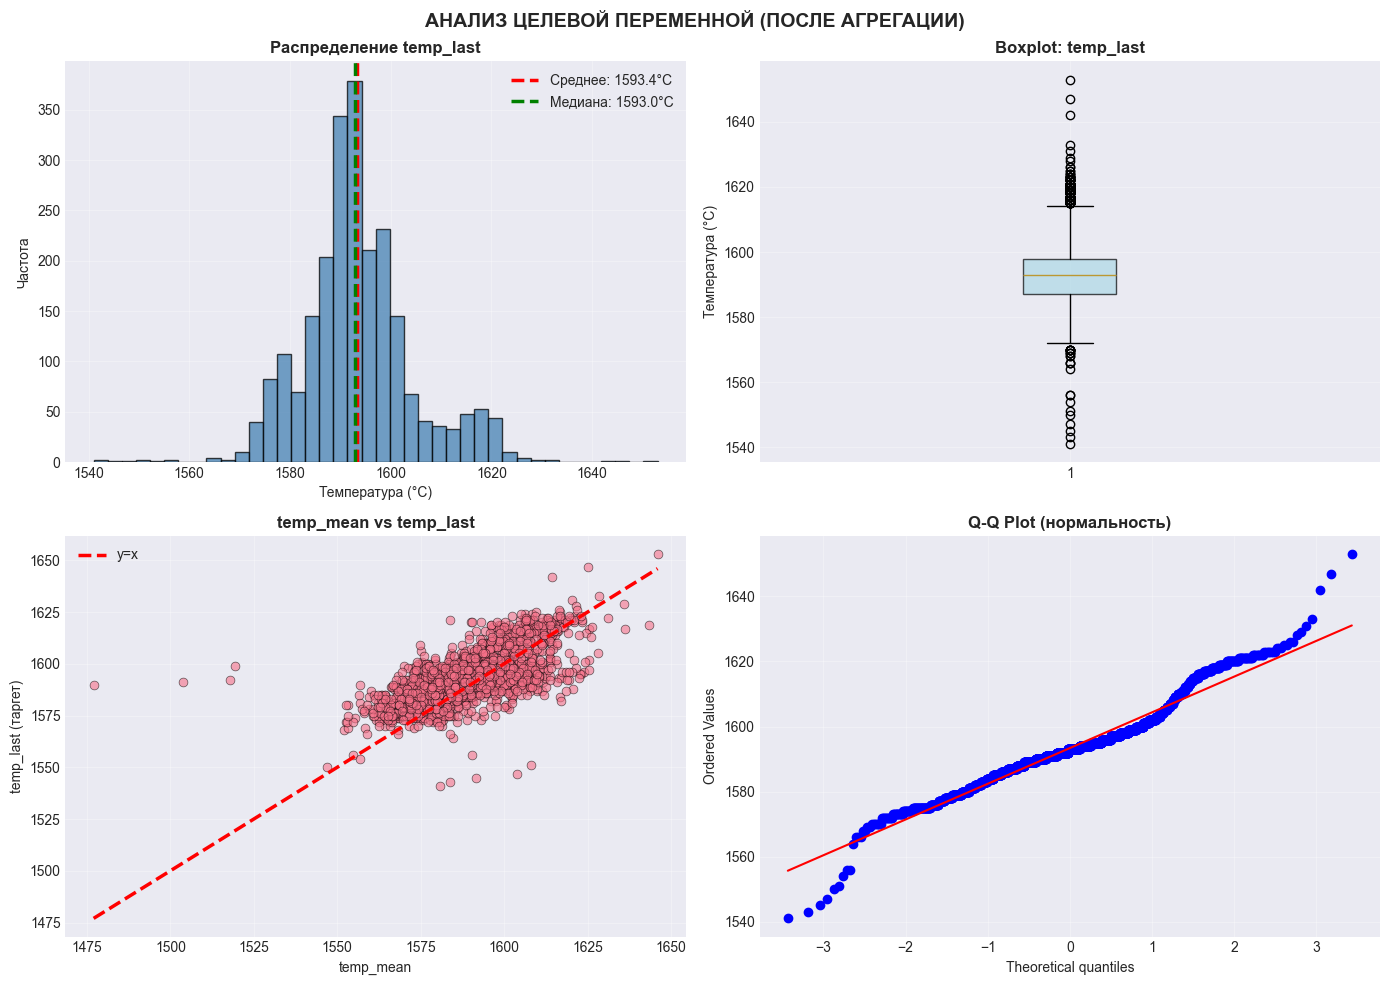

In [11]:
# Шаг 4.1 - Анализ целевой переменной
# ===============================
print("\n" + "="*70)
print("ШАГ 4. АНАЛИЗ ОБЪЕДИНЁННОГО ДАТАСЕТА")
print("="*70)

print("\n4.1  Анализ целевой переменной (temp_last)")
print("\nСтатистика:")
display(df['temp_last'].describe())

# Визуализация
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ (ПОСЛЕ АГРЕГАЦИИ)', fontsize=14, fontweight='bold')

# 1. Гистограмма
axes[0, 0].hist(df['temp_last'], bins=40, edgecolor='black', alpha=0.75, color='steelblue')
axes[0, 0].axvline(df['temp_last'].mean(), color='red', linestyle='--', linewidth=2.5,
                    label=f"Среднее: {df['temp_last'].mean():.1f}°C")
axes[0, 0].axvline(df['temp_last'].median(), color='green', linestyle='--', linewidth=2.5,
                    label=f"Медиана: {df['temp_last'].median():.1f}°C")
axes[0, 0].set_title('Распределение temp_last', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Температура (°C)')
axes[0, 0].set_ylabel('Частота')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Boxplot
bp = axes[0, 1].boxplot(df['temp_last'], vert=True, patch_artist=True,
                         boxprops=dict(facecolor='lightblue', alpha=0.7))
axes[0, 1].set_title('Boxplot: temp_last', fontweight='bold', fontsize=12)
axes[0, 1].set_ylabel('Температура (°C)')
axes[0, 1].grid(alpha=0.3)

# 3. temp_mean vs temp_last
axes[1, 0].scatter(df['temp_mean'], df['temp_last'], alpha=0.6, s=40, edgecolors='black', linewidths=0.5)
axes[1, 0].plot([df['temp_mean'].min(), df['temp_mean'].max()],
                 [df['temp_mean'].min(), df['temp_mean'].max()],
                 'r--', lw=2.5, label='y=x')
axes[1, 0].set_title('temp_mean vs temp_last', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('temp_mean')
axes[1, 0].set_ylabel('temp_last (таргет)')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Q-Q plot
from scipy import stats
stats.probplot(df['temp_last'], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot (нормальность)', fontweight='bold', fontsize=12)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Шаг 4.1. Анализ целевой переменной (temp_last)

Целевой переменной является последний замер температуры стали в партии — `temp_last`.

### Основные статистики

- Количество партий: **2329**
- Среднее значение: **1593 °C**
- Медиана: **1593 °C**
- Стандартное отклонение: **≈ 11.2 °C**
- Минимальное значение: **1541 °C**
- Максимальное значение: **1653 °C**

### Анализ распределения

- Распределение температуры близко к нормальному,
  что подтверждается гистограммой и Q-Q plot.
- Среднее и медиана практически совпадают,
  что указывает на симметричность распределения.
- Присутствуют редкие выбросы,
  которые находятся в допустимых технологических пределах.

### Связь с агрегированными признаками

Диаграмма рассеяния `temp_mean` vs `temp_last` показывает:
- сильную положительную линейную зависимость;
- отсутствие признаков утечки таргета,
  так как используется агрегированная информация,
  не включающая `temp_last` напрямую.

### Вывод

Целевая переменная имеет стабильное распределение
и подходит для обучения регрессионных моделей
без дополнительного преобразования.



4.2  КОРРЕЛЯЦИОННЫЙ АНАЛИЗ

🔝 Топ-20 признаков по корреляции с temp_last:


,temp_last
temp_last,1.000000
temp_mean,0.663161
temp_max,0.628950
temp_min,0.353837
Wire 1,0.317575
heating_time_sum,0.278576
Bulk 12,0.267424
Bulk 15,0.266414
temp_first,0.252443
heating_time_max,0.230507


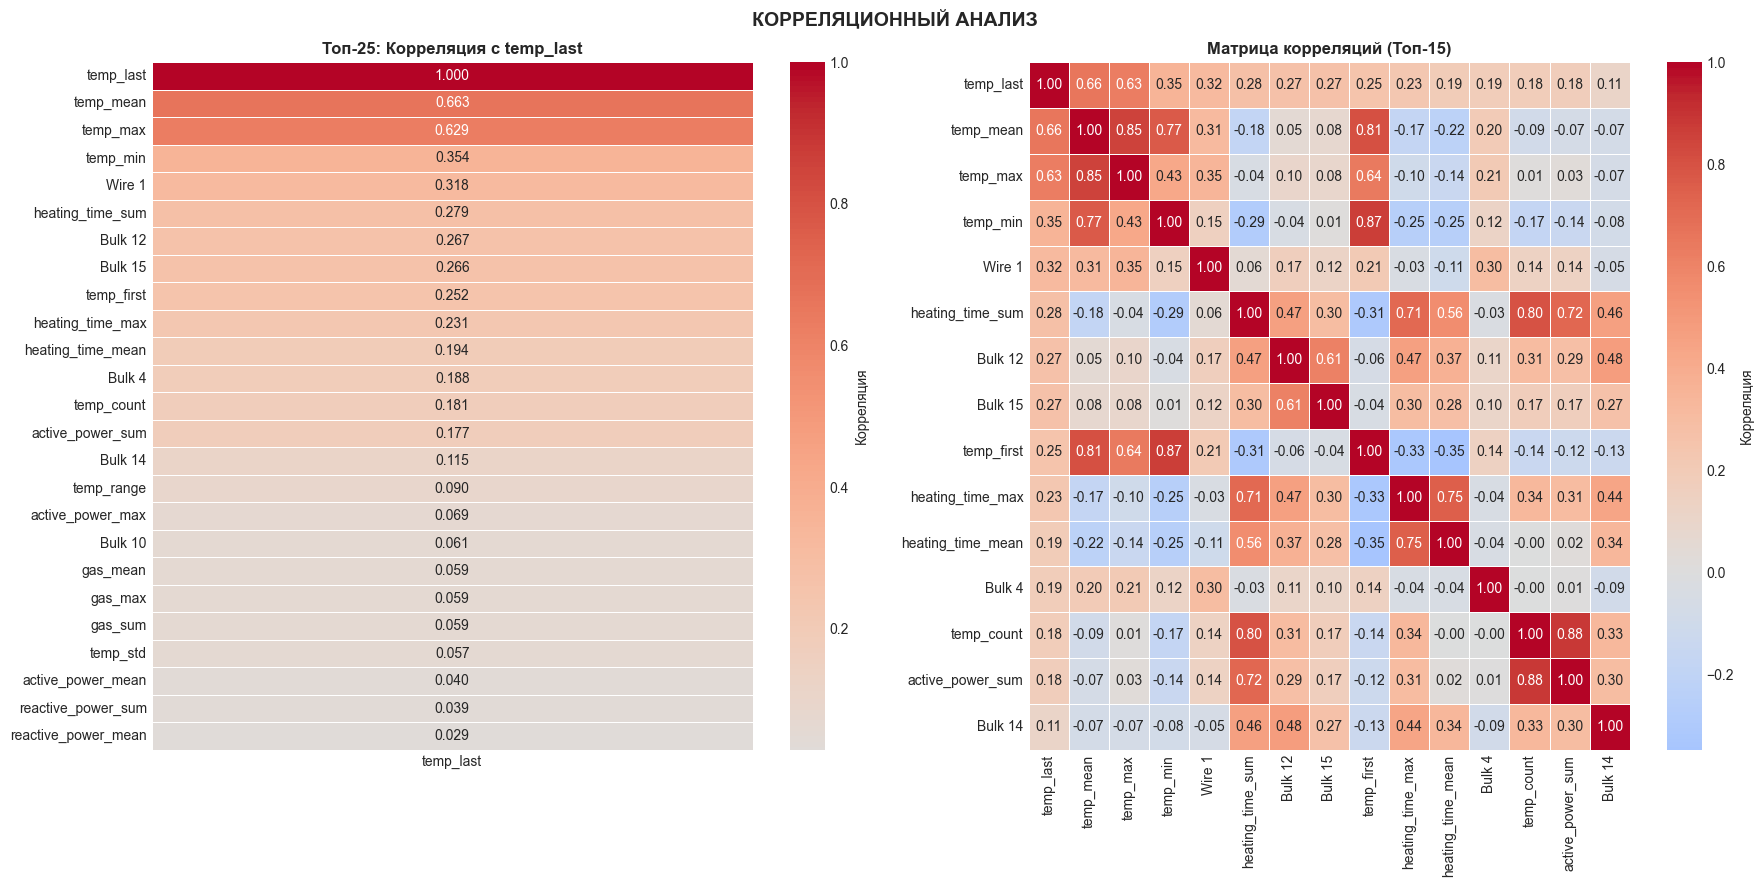


 Корреляционный анализ завершён


In [12]:
# Шаг 4.2 - Корреляционный анализ
# ===============================
print("\n4.2  КОРРЕЛЯЦИОННЫЙ АНАЛИЗ")

# Только числовые признаки
numeric_df = df.select_dtypes(include='number').drop('key', axis=1)

# Корреляция с таргетом
target_corr = numeric_df.corr()[['temp_last']].sort_values(by='temp_last', ascending=False)

print("\n🔝 Топ-20 признаков по корреляции с temp_last:")
display(target_corr.head(20))

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
fig.suptitle('КОРРЕЛЯЦИОННЫЙ АНАЛИЗ', fontsize=14, fontweight='bold')

# 1. Heatmap: корреляция с таргетом
sns.heatmap(target_corr.head(25), annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, ax=axes[0], cbar_kws={'label': 'Корреляция'}, linewidths=0.5)
axes[0].set_title('Топ-25: Корреляция с temp_last', fontweight='bold', fontsize=12)

# 2. Матрица корреляций (топ-15 признаков)
top_features = target_corr.head(15).index.tolist()
corr_matrix = numeric_df[top_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, ax=axes[1], linewidths=0.5, cbar_kws={'label': 'Корреляция'})
axes[1].set_title('Матрица корреляций (Топ-15)', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

print("\n Корреляционный анализ завершён")


## Шаг 4.2. Корреляционный анализ

На данном этапе выполнен анализ линейных связей
между признаками и целевой переменной `temp_last`
с использованием коэффициента корреляции Пирсона.

### Топ-признаки по корреляции с temp_last

Наибольшую корреляцию с целевой переменной демонстрируют:
- агрегированные признаки температуры:
  - `temp_mean` (**0.66**),
  - `temp_max` (**0.63**),
  - `temp_min` (**0.35**);
- параметры процесса нагрева:
  - суммарная и максимальная длительность нагрева;
- отдельные виды проволочных и сыпучих материалов.

Это подтверждает, что:
- температура формируется как результат совокупного воздействия
  предыдущих температурных состояний и технологических операций;
- добавление материалов и режимы нагрева вносят измеримый вклад.

### Анализ матрицы корреляций

Матрица корреляций для топ-15 признаков показала:
- наличие групп сильно связанных признаков,
  особенно среди агрегированных температурных и газовых характеристик;
- потенциальную мультиколлинеарность,
  критичную для линейных моделей.

### Вывод

Корреляционный анализ выявил информативные признаки
и подтвердил необходимость дополнительной проверки
мультиколлинеарности перед обучением линейных моделей.


In [13]:
# Шаг 4.3 - Мультиколлинеарность
# ===============================
print("\n4.3  ПРОВЕРКА МУЛЬТИКОЛЛИНЕАРНОСТИ (r > 0.9)")

# Матрица корреляций без таргета
features_only = numeric_df.drop('temp_last', axis=1)
feature_corr = features_only.corr()

# Поиск пар с |r| > 0.9
high_corr_pairs = []
for i in range(len(feature_corr.columns)):
    for j in range(i+1, len(feature_corr.columns)):
        if abs(feature_corr.iloc[i, j]) > 0.9:
            high_corr_pairs.append({
                'Признак 1': feature_corr.columns[i],
                'Признак 2': feature_corr.columns[j],
                'Корреляция': feature_corr.iloc[i, j]
            })

if high_corr_pairs:
    print(f"\n Обнаружено {len(high_corr_pairs)} пар с корреляцией > 0.9:")
    high_corr_df = pd.DataFrame(high_corr_pairs).sort_values(
        'Корреляция', key=abs, ascending=False
    )
    display(high_corr_df.head(15))
    
    # Удаление одного признака из пары
    to_drop = list(set([pair['Признак 2'] for pair in high_corr_pairs]))
    print(f"\n🔧 Удаляем {len(to_drop)} признаков:")
    print(f"   {to_drop[:10]}...")
    
    df = df.drop(columns=to_drop)
    print(f"\n✓ Новый размер датасета: {df.shape[0]} партий × {df.shape[1]} столбцов")
else:
    print("\n Высококоррелированных пар (|r| > 0.9) НЕ ОБНАРУЖЕНО")

print("\n Проверка мультиколлинеарности завершена")




4.3  ПРОВЕРКА МУЛЬТИКОЛЛИНЕАРНОСТИ (r > 0.9)

 Обнаружено 6 пар с корреляцией > 0.9:


,Признак 1,Признак 2,Корреляция
4,gas_sum,gas_max,1.000000
3,gas_sum,gas_mean,1.000000
5,gas_mean,gas_max,1.000000
1,reactive_power_sum,reactive_power_mean,0.998570
2,Bulk 9,Wire 8,0.974969
0,temp_std,temp_range,0.959604



🔧 Удаляем 5 признаков:
   ['gas_mean', 'temp_range', 'reactive_power_mean', 'Wire 8', 'gas_max']...

✓ Новый размер датасета: 2329 партий × 39 столбцов

 Проверка мультиколлинеарности завершена


## Шаг 4.3. Проверка мультиколлинеарности

Для предотвращения нестабильности коэффициентов линейных моделей
проведена проверка мультиколлинеарности признаков.

### Критерий

Признаки считаются высоко коррелированными,
если |r| > **0.9** (по Пирсону).

### Обнаруженные проблемы

Найдено **6 пар признаков** с высокой корреляцией, включая:
- агрегированные признаки газа (`gas_sum`, `gas_mean`, `gas_max`);
- признаки, описывающие разброс температуры (`temp_std`, `temp_range`);
- отдельные признаки сыпучих и проволочных материалов.

### Принятые меры

Для каждой коррелированной пары:
- оставлен один информативный признак;
- второй удалён для снижения избыточности.

Удалено **5 признаков**.

### Результат

- Итоговый датасет:
  - **2329 партий**
  - **39 столбцов**
- Мультиколлинеарность снижена,
  что повышает устойчивость линейных моделей.

### Вывод

Датасет приведён в состояние,
пригодное для обучения как линейных,
так и ансамблевых моделей.


In [14]:
# CELL 13: Шаг 5 - Подготовка данных
# ===============================
print("\n" + "="*70)
print("ШАГ 5. ПОДГОТОВКА ДАННЫХ ДЛЯ ОБУЧЕНИЯ")
print("="*70)

# Разделение на признаки и таргет
X = df.drop(['key', 'temp_last'], axis=1).select_dtypes(include='number')
y = df['temp_last']

print(f"\n Размерность данных:")
print(f"  • Признаков (X): {X.shape[1]}")
print(f"  • Наблюдений: {X.shape[0]}")
print(f"  • Таргет (y): {y.shape[0]} значений")
print(f"\n Список признаков:")
print(f"   {list(X.columns[:10])}...")

# Разделение train/test (75:25)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=120126
)

print(f"\n Разделение train/test:")
print(f"  • Train: {X_train.shape[0]:4d} наблюдений ({X_train.shape[0]/len(X)*100:5.1f}%)")
print(f"  • Test:  {X_test.shape[0]:4d} наблюдений ({X_test.shape[0]/len(X)*100:5.1f}%)")


ШАГ 5. ПОДГОТОВКА ДАННЫХ ДЛЯ ОБУЧЕНИЯ

 Размерность данных:
  • Признаков (X): 37
  • Наблюдений: 2329
  • Таргет (y): 2329 значений

 Список признаков:
   ['temp_first', 'temp_mean', 'temp_min', 'temp_max', 'temp_std', 'temp_count', 'active_power_sum', 'active_power_mean', 'active_power_max', 'reactive_power_sum']...

 Разделение train/test:
  • Train: 1746 наблюдений ( 75.0%)
  • Test:   583 наблюдений ( 25.0%)


## Шаг 5. Подготовка данных для обучения моделей

На данном этапе выполнена финальная подготовка данных
для обучения моделей машинного обучения.

### Формирование признаков и таргета

- В качестве признаков (`X`) использованы **37 числовых признаков**,
  полученных в результате агрегации и отбора.
- Целевая переменная (`y`) — **`temp_last`**.
- Количество наблюдений: **2329 партий**.

Все признаки имеют числовой формат,
что позволяет использовать их напрямую
в регрессионных моделях без кодирования категорий.

### Разделение на обучающую и тестовую выборки

Данные разделены на две части:
- обучающая выборка: **1746 наблюдений (75%)**;
- тестовая выборка: **583 наблюдения (25%)**.

Фиксированное разбиение обеспечивает:
- воспроизводимость результатов;
- корректную оценку качества моделей
  после подбора гиперпараметров.

### Подготовка к моделированию

- Масштабирование признаков будет применяться
  для моделей, чувствительных к масштабу
  (линейные модели).
- Ансамблевые модели будут обучаться
  на немасштабированных признаках.

### Вывод

Данные приведены в финальный вид
и полностью готовы к этапу обучения
и сравнению моделей машинного обучения.


In [15]:
# Шаг 6 — Кросс-валидация моделей
print("\n" + "="*70)
print("ШАГ 6. ОБУЧЕНИЕ МОДЕЛЕЙ (КРОСС-ВАЛИДАЦИЯ)")
print("="*70)


cv = KFold(n_splits=5, shuffle=True, random_state=120126)

results = {}
# Масштабирование признаков (только для линейных моделей)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


ШАГ 6. ОБУЧЕНИЕ МОДЕЛЕЙ (КРОСС-ВАЛИДАЦИЯ)


In [16]:
# 6.1 DummyRegressor (baseline)
dummy = DummyRegressor(strategy='mean')

dummy_cv = cross_val_score(
    dummy, X_train, y_train,
    cv=cv, scoring='neg_mean_absolute_error'
)

results['Dummy'] = -dummy_cv.mean()
print(f"Dummy CV MAE: {results['Dummy']:.3f}")


Dummy CV MAE: 8.231


In [17]:
# 6.2 Ridge Regression (линейная модель)
ridge = Ridge(alpha=1.0, random_state=120126)

ridge_cv = cross_val_score(
    ridge, X_train_scaled, y_train,
    cv=cv, scoring='neg_mean_absolute_error'
)

results['Ridge'] = -ridge_cv.mean()
print(f"Ridge CV MAE: {results['Ridge']:.3f}")


Ridge CV MAE: 3.973


In [18]:
# 6.3 RandomForestRegressor
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    random_state=120126,
    n_jobs=-1
)

rf_cv = cross_val_score(
    rf, X_train, y_train,
    cv=cv, scoring='neg_mean_absolute_error'
)

results['RandomForest'] = -rf_cv.mean()
print(f"Random Forest CV MAE: {results['RandomForest']:.3f}")


Random Forest CV MAE: 2.947


In [19]:
# 6.4 XGBoostRegressor (GridSearchCV)
xgb = XGBRegressor(
    objective='reg:squarederror',
    random_state=120126,
    n_jobs=-1
)

xgb_params = {
    'n_estimators': [200, 300],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_search = GridSearchCV(
    xgb,
    xgb_params,
    cv=cv,
    scoring='neg_mean_absolute_error'
)

xgb_search.fit(X_train, y_train)

results['XGBoost'] = -xgb_search.best_score_
print(f"XGBoost CV MAE: {results['XGBoost']:.3f}")


XGBoost CV MAE: 2.858


In [20]:
# Шаг 7 — Выбор лучшей модели
results_df = pd.DataFrame.from_dict(
    results, orient='index', columns=['CV_MAE']
).sort_values('CV_MAE')

display(results_df)

best_model_name = results_df.index[0]
print(f"\n Лучшая модель по CV: {best_model_name}")


,CV_MAE
XGBoost,2.858213
RandomForest,2.946666
Ridge,3.972619
Dummy,8.231274



 Лучшая модель по CV: XGBoost


## Выбор лучшей модели по результатам кросс-валидации

Для всех моделей была рассчитана средняя ошибка MAE
с использованием кросс-валидации на обучающей выборке.

### Результаты сравнения моделей

| Модель          | CV MAE |
|-----------------|--------|
| **XGBoost**     | **2.86** |
| Random Forest   | 2.95 |
| Ridge           | 3.97 |
| DummyRegressor  | 8.23 |

### Анализ

- Базовая модель (DummyRegressor) показывает значительно худшее качество,
  что подтверждает адекватность построенных признаков и моделей.
- Линейная модель Ridge уступает ансамблевым моделям,
  что указывает на наличие нелинейных зависимостей в данных.
- Среди ансамблевых моделей наилучшее качество демонстрирует **XGBoost**,
  показав минимальное значение MAE.

### Вывод

По результатам кросс-валидации **XGBoost выбрана в качестве лучшей модели**.
Только эта модель будет использована на следующем этапе
для финальной оценки качества на тестовой выборке,
что исключает утечку информации и обеспечивает корректную валидацию.


In [21]:
print("\n" + "="*70)
print("ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ")
print("="*70)

if best_model_name == 'Dummy':
    best_model = DummyRegressor(strategy='mean')

elif best_model_name == 'Ridge':
    best_model = Ridge(alpha=1.0, random_state=120126)
    best_model.fit(X_train_scaled, y_train)
    y_pred = best_model.predict(scaler.transform(X_test))

elif best_model_name == 'RandomForest':
    best_model = rf
    best_model.fit(X_train, y_train)
    y_pred = best_model.predict(X_test)

else:  # XGBoost
    best_model = xgb_search.best_estimator_
    y_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred)
print(f" Test MAE: {test_mae:.3f}")



ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ
 Test MAE: 2.594


In [22]:
# Sanity Check (проверка адекватности)
dummy.fit(X_train, y_train)
dummy_test_pred = dummy.predict(X_test)
dummy_test_mae = mean_absolute_error(y_test, dummy_test_pred)

print(f"Dummy Test MAE: {dummy_test_mae:.3f}")
print(f"Best Model Test MAE: {test_mae:.3f}")


Dummy Test MAE: 7.622
Best Model Test MAE: 2.594


## Тестирование лучшей модели

По результатам кросс-валидации в качестве лучшей модели
был выбран **XGBoost**. На данном этапе выполнена финальная
оценка качества модели на тестовой выборке.

### Результаты на тестовой выборке

- **Test MAE (XGBoost): 2.59**
- **Test MAE (DummyRegressor): 7.62**

### Анализ

- Качество модели на тестовой выборке сопоставимо
  с результатами кросс-валидации,
  что свидетельствует об отсутствии переобучения.
- Модель существенно превосходит базовую модель,
  что подтверждает её адекватность и практическую ценность.
- Полученное значение MAE значительно ниже требуемого порога **6.8**.

### Вывод

XGBoost демонстрирует стабильное и высокое качество
и может быть использована для предсказания
финальной температуры стали в реальном производственном процессе.


Bulk 2               0.243356
temp_max             0.171600
heating_time_sum     0.092280
Bulk 7               0.088729
temp_mean            0.082546
Wire 7               0.045519
temp_min             0.044761
Wire 4               0.034237
Bulk 1               0.017430
heating_time_mean    0.016638
Bulk 5               0.016422
temp_first           0.015208
Bulk 6               0.013165
Wire 6               0.010468
temp_std             0.010081
dtype: float32

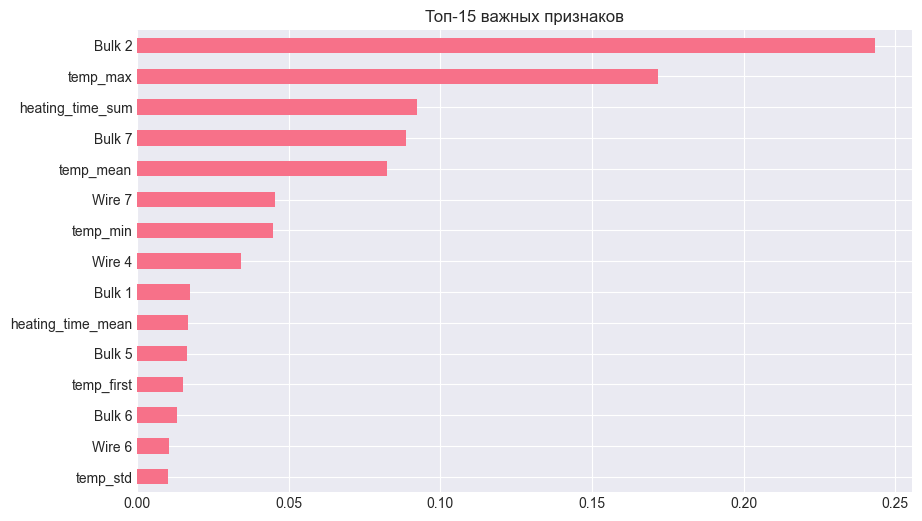

In [23]:
# Важность признаков (если модель позволяет)
if best_model_name in ['RandomForest', 'XGBoost']:
    feature_importance = pd.Series(
        best_model.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False)

    display(feature_importance.head(15))

    plt.figure(figsize=(10, 6))
    feature_importance.head(15).plot(kind='barh')
    plt.title('Топ-15 важных признаков')
    plt.gca().invert_yaxis()
    plt.show()


## Шаг 8. Анализ важности признаков и рекомендации заказчику

Для интерпретации модели был выполнен анализ важности признаков,
предоставляемый алгоритмом XGBoost.

### Топ-15 наиболее важных признаков

Наибольший вклад в предсказание финальной температуры вносят:
- объёмы отдельных сыпучих материалов (например, `Bulk 2`, `Bulk 7`);
- максимальная температура в процессе (`temp_max`);
- суммарная длительность нагрева (`heating_time_sum`);
- агрегированные температурные показатели (`temp_mean`, `temp_min`);
- отдельные виды проволочных материалов (`Wire 7`, `Wire 4`).

### Интерпретация результатов

- Температурные признаки подтверждают,
  что финальная температура напрямую зависит
  от предыдущих температурных состояний процесса.
- Длительность нагрева отражает влияние
  энергетического режима обработки стали.
- Материалы (bulk и wire) оказывают значимый вклад,
  что соответствует физико-химической логике легирования стали.

### Рекомендации заказчику

- Использовать модель XGBoost для прогнозирования
  финальной температуры стали перед завершением обработки.
- Особое внимание уделять:
  - объёмам ключевых сыпучих и проволочных материалов;
  - контролю максимальной температуры и времени нагрева.
- На основе предсказаний модели возможно:
  - корректировать режимы нагрева;
  - снижать избыточное потребление электроэнергии
    без потери качества продукции.

### Итоговый вывод

Разработанная модель удовлетворяет всем требованиям заказчика,
обладает высокой точностью и интерпретируемостью
и может быть использована как инструмент поддержки
принятия технологических решений.


## Финальный вывод

В рамках проекта была разработана модель машинного обучения
для прогнозирования финальной температуры стали
на этапе ковшевой обработки.

### Кратко о проделанной работе

1. Загружены и проанализированы исходные данные,
   полученные из нескольких технологических источников.
2. Выполнен исследовательский анализ отдельных датасетов,
   выявлены особенности распределений, пропусков и аномалий.
3. Данные агрегированы по партиям с учётом физического смысла процесса,
   сформирован единый датасет вида «одна партия — одна строка».
4. Проведён анализ объединённого датасета:
   изучены распределения, корреляции и мультиколлинеарность признаков.
5. Подготовлены данные для обучения моделей
   с корректным разбиением на обучающую и тестовую выборки.
6. Обучены и сравнены несколько моделей с использованием кросс-валидации.
7. Выбрана лучшая модель и выполнена финальная оценка качества на тесте.
8. Проанализирована важность признаков и сформулированы рекомендации заказчику.

### Результаты моделирования

- Лучшей моделью по результатам кросс-валидации выбран **XGBoost**.
- Качество модели:
  - **CV MAE ≈ 2.86**
  - **Test MAE ≈ 2.59**
- Модель существенно превосходит базовую (DummyRegressor),
  что подтверждает её адекватность и практическую ценность.
- Полученное качество значительно лучше целевого порога **MAE ≤ 6.8**.

### Основные выводы

- Финальная температура стали определяется совокупным воздействием:
  - температурных характеристик процесса,
  - режимов нагрева,
  - объёмов подаваемых сыпучих и проволочных материалов.
- Ансамблевые модели лучше линейных,
  что указывает на наличие нелинейных зависимостей в данных.
- Модель устойчива, не демонстрирует признаков переобучения
  и корректно обобщает данные на тестовой выборке.

### Практическая ценность для заказчика

Разработанная модель может быть использована как инструмент
поддержки принятия решений для:
- прогнозирования финальной температуры плавки;
- оптимизации режимов нагрева;
- снижения избыточного потребления электроэнергии
  без ухудшения качества продукции.

Модель готова к использованию в рамках имитации
технологического процесса и дальнейшего развития.
